# Checkpoint 2: Implementation Results and Evaluation

## Part 1: Model Training

We will train a constant baseline and Random Forest regression model to compare and predict gene dependency scores using existing training and validation sets.

In [3]:
# Load data from Checkpoint 1
from pathlib import Path
import pandas as pd

data_folder = Path(".")

train = pd.read_csv(data_folder / "checkpoint1_train.csv").set_index("sample")
val = pd.read_csv(data_folder / "checkpoint1_validation.csv").set_index("sample")

# Define features and target
feature_cols = [
    "mean_expression",
    "enrichment",
    "expression_variability",
    "amplification_frequency",
]

target_col = "dependency_score"

# Training and validation data
X_train = train[feature_cols]
y_train = train[target_col]

X_val = val[feature_cols]
y_val = val[target_col]

print("Training Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)

Training Shape: (1400, 4)
Validation Shape: (300, 4)


In [4]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor

# Constant Baseline
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

# Random Forest
rand_forest = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
rand_forest.fit(X_train, y_train)

# Predict dependency scores on validation set (15% of the total dataset)
baseline_pred = baseline.predict(X_val)
rand_forest_pred = rand_forest.predict(X_val)

# Evaluate performance with Mean Absolute Error (MAE) and Spearman Correlation
for name, predictions in [
    ("Constant Baseline", baseline_pred),
    ("Random Forest", rand_forest_pred)
]:
    mae = mean_absolute_error(y_val, predictions)
    spearman_corr = spearmanr(y_val, predictions).statistic

    print(name)
    print("Mean Absolute Error (MAE):", mae)
    print("Spearman Correlation:", spearman_corr)
    print()

Constant Baseline
Mean Absolute Error (MAE): 0.2354602187284226
Spearman Correlation: nan

Random Forest
Mean Absolute Error (MAE): 0.2190226867053093
Spearman Correlation: 0.4115921288014311



/var/folders/54/4rmgmq8n02zg15qd9jgvd3j00000gn/T/ipykernel_45683/3540703589.py:27: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_corr = spearmanr(y_val, predictions).statistic


## Part 2: Model Tuning

In [5]:
validation_data = pd.read_csv("checkpoint1_validation.csv")
surface_mask = validation_data["is_surface"].to_numpy()

for depth in [5, 10, 20, None]:
    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=depth,
        random_state=42
    )
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)

    # Validation Results
    mae = mean_absolute_error(y_val, y_pred)
    spearman_corr = spearmanr(y_val, y_pred).statistic

    # Surface Validation Results
    surface_actual = y_val[surface_mask]
    surface_pred = y_pred[surface_mask]

    surface_mae = mean_absolute_error(surface_actual, surface_pred)
    surface_spearman_corr = spearmanr(surface_actual, surface_pred).statistic

    print("Max Depth:", depth)
    print("Mean Absolute Error (MAE):", mae)
    print("Spearman Correlation:", spearman_corr)
    print("Surface Mean Absolute Error (MAE):", surface_mae)
    print("Surface Spearman Correlation:", surface_spearman_corr)
    print()


Max Depth: 5
Mean Absolute Error (MAE): 0.2040102099835366
Spearman Correlation: 0.40074160832249583
Surface Mean Absolute Error (MAE): 0.1670611313609598
Surface Spearman Correlation: 0.44676660466134144

Max Depth: 10
Mean Absolute Error (MAE): 0.2154145838313599
Spearman Correlation: 0.3987386526516961
Surface Mean Absolute Error (MAE): 0.17030961394910338
Surface Spearman Correlation: 0.4172228909071014

Max Depth: 20
Mean Absolute Error (MAE): 0.2196874185571645
Spearman Correlation: 0.41058100645562723
Surface Mean Absolute Error (MAE): 0.17613023366009234
Surface Spearman Correlation: 0.42510121457489874

Max Depth: None
Mean Absolute Error (MAE): 0.2190226867053093
Spearman Correlation: 0.4115921288014311
Surface Mean Absolute Error (MAE): 0.17251065717794037
Surface Spearman Correlation: 0.4222562643615275



## Part 3: Final Random Forest Model

Using a validation set, the Random Forest model was tuned to observe higher Spearman correlation results and lower Mean Absolute Error (MAE) results with maximum tree depths of 5, 10, 20, and None. Surface-level validation genes (38 genes) with a maximum tree depth of 5 showed the highest spearman correlation (0.4468) and lowest MAE (0.1671). The maximum tree depth of 5 also showed the lowest overall validation MAE (0.2040). 

In [6]:
best_random_forest = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

best_random_forest.fit(X_train, y_train)

print("Best Random Forest Model trained with max_depth=5")

Best Random Forest Model trained with max_depth=5


## Part 4: Compare Baseline and Random Forest on Surface Genes

In [7]:
baseline_pred = baseline.predict(X_val)
rand_forest_pred = best_random_forest.predict(X_val)

for name, predictions in [
    ("Constant Baseline", baseline_pred),
    ("Random Forest", rand_forest_pred)
]:
    surface_actual = y_val[surface_mask]
    surface_pred = predictions[surface_mask]

    mae = mean_absolute_error(surface_actual, surface_pred)

    print(name)
    print("Surface Mean Absolute Error (MAE):", round(mae, 4))

    if name == "Random Forest":
        spearman_corr = spearmanr(surface_actual, surface_pred).statistic
        print("Surface Spearman Correlation:", round(spearman_corr, 4))
    
    print()

Constant Baseline
Surface Mean Absolute Error (MAE): 0.197

Random Forest
Surface Mean Absolute Error (MAE): 0.1671
Surface Spearman Correlation: 0.4468



The Random Forest model with a max_depth of 5 produces approximately 15.2% lower prediction error than the constant baseline on the 38 surface level validation genes.

## Part 5: Ridge Model

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import joblib

# Folder containing the Checkpoint 1 output files
data_folder = Path(".")

train = pd.read_csv(data_folder / "checkpoint1_train.csv", index_col=0)
val = pd.read_csv(data_folder / "checkpoint1_validation.csv", index_col=0)

print("Training genes:", len(train))
print("Validation genes:", len(val))
print("Training surface genes:", train["is_surface"].sum())
print("Validation surface genes:", val["is_surface"].sum())

Training genes: 1400
Validation genes: 300
Training surface genes: 175
Validation surface genes: 38


In [9]:
feature_cols = ["mean_expression", "enrichment", "expression_variability", "amplification_frequency"]

target_col = "dependency_score"

X_train = train[feature_cols]
y_train = train[target_col]

X_val = val[feature_cols]
y_val = val[target_col]

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

Training shape: (1400, 4)
Validation shape: (300, 4)


In [10]:
alphas = [0.01, 0.1, 1, 10, 100, 1000, 10000]

results = []
models = {}

# Fit the model for each alpha and evaluate on the validation set
for alpha in alphas:
    model = Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler()),
                      ("ridge", Ridge(alpha=alpha))])

    model.fit(X_train, y_train)
    predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, predictions)

    results.append({"alpha": alpha, "validation_MAE": mae})
    
    models[alpha] = model

tuning_results = pd.DataFrame(results)

# Display the tuning results sorted by validation MAE
display(tuning_results.sort_values("validation_MAE"))

best_alpha = tuning_results.loc[tuning_results["validation_MAE"].idxmin(), "alpha"]

# Print the best alpha and retrieve the corresponding model
best_model = models[best_alpha]

print("Best alpha:", best_alpha)

,alpha,validation_MAE
5,1000.00,0.218958
4,100.00,0.227533
6,10000.00,0.228424
3,10.00,0.229831
2,1.00,0.230097
1,0.10,0.230124
0,0.01,0.230127


Best alpha: 1000.0


In [11]:
val_predictions = best_model.predict(X_val)

# Evaluate the best model on the validation set 
def evaluate(y_true, y_pred):
    rho = spearmanr(y_true, y_pred).statistic
    return {"MAE": mean_absolute_error(y_true, y_pred), "Spearman": rho}

surface_mask = val["is_surface"].astype(bool).to_numpy()

overall_metrics = evaluate(y_val, val_predictions)
surface_metrics = evaluate(y_val.to_numpy()[surface_mask], val_predictions[surface_mask])

ridge_results = pd.DataFrame([{"Subset": "Overall", **overall_metrics},
                              {"Subset": "Surface", **surface_metrics}])

display(ridge_results)

,Subset,MAE,Spearman
0,Overall,0.218958,0.414054
1,Surface,0.184010,0.358792


In [35]:
output_folder = Path("checkpoint2_ridge_outputs")
output_folder.mkdir(exist_ok=True)

# Save the best Ridge Regression model and results to the output folder
joblib.dump(best_model, output_folder / "ridge_model.joblib")

print("Ridge model and results saved.")

Ridge model and results saved.


In [14]:
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)

from scipy.stats import spearmanr, pearsonr

val_predictions = best_model.predict(X_val)

def detailed_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "Spearman": spearmanr(y_true, y_pred).statistic,
        "Pearson": pearsonr(y_true, y_pred).statistic
    }

surface_mask = val["is_surface"].astype(bool).to_numpy()

metrics_table = pd.DataFrame([
    {
        "Subset": "All validation genes",
        "Count": len(y_val),
        **detailed_metrics(y_val, val_predictions)
    },
    {
        "Subset": "Surface genes",
        "Count": surface_mask.sum(),
        **detailed_metrics(
            y_val.to_numpy()[surface_mask],
            val_predictions[surface_mask]
        )
    }
])

display(metrics_table.round(4))


,Subset,Count,MAE,RMSE,R2,Spearman,Pearson
0,All validation genes,300,0.219,0.3634,0.1166,0.4141,0.3519
1,Surface genes,38,0.184,0.2221,-0.0334,0.3588,0.3599


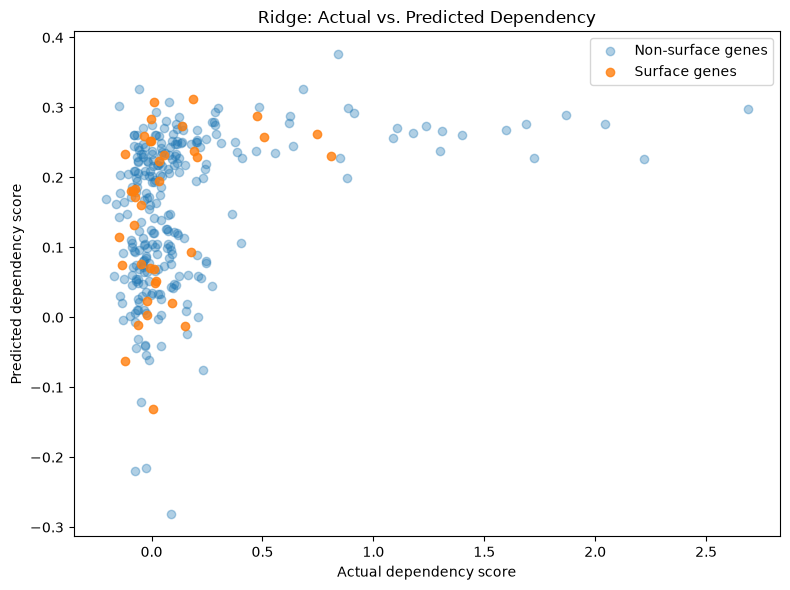

In [15]:
actual = y_val.to_numpy()

plt.figure(figsize=(8, 6))

plt.scatter(
    actual[~surface_mask], val_predictions[~surface_mask],
    alpha=0.35, label="Non-surface genes")

plt.scatter(actual[surface_mask], val_predictions[surface_mask],
    alpha=0.8, label="Surface genes")

limits = [min(actual.min(), val_predictions.min()),
    max(actual.max(), val_predictions.max())]

plt.xlabel("Actual dependency score")
plt.ylabel("Predicted dependency score")
plt.title("Ridge: Actual vs. Predicted Dependency")
plt.legend()
plt.tight_layout()
plt.show()

,Feature,Coefficient,Absolute coefficient
0,mean_expression,0.068017,0.068017
2,expression_variability,-0.048180,0.048180
1,enrichment,0.038065,0.038065
3,amplification_frequency,-0.001373,0.001373


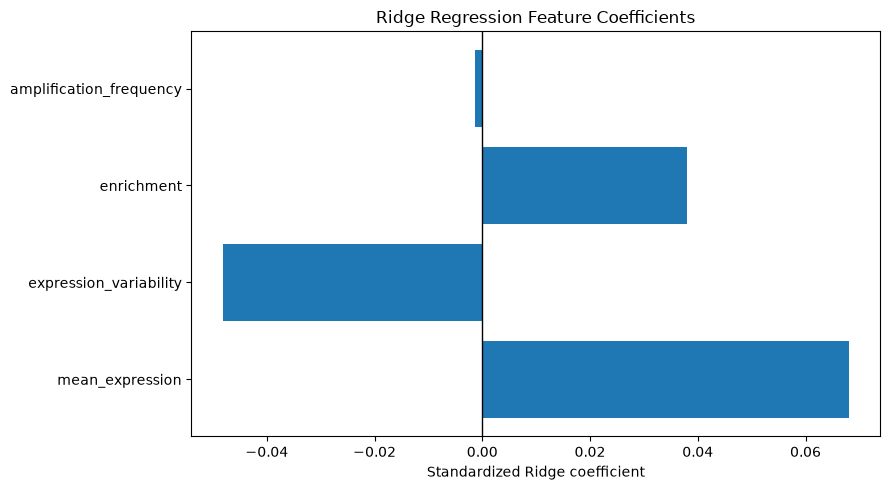

In [16]:
# Display the feature importance based on the coefficients of the Ridge regression model

coefficients = best_model.named_steps["ridge"].coef_

feature_importance = pd.DataFrame({
    "Feature": feature_cols,
    "Coefficient": coefficients,
    "Absolute coefficient": np.abs(coefficients)
}).sort_values("Absolute coefficient", ascending=False)

display(feature_importance)

plt.figure(figsize=(9, 5))

plt.barh(feature_importance["Feature"], feature_importance["Coefficient"])

plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Standardized Ridge coefficient")
plt.title("Ridge Regression Feature Coefficients")
plt.tight_layout()
plt.show()

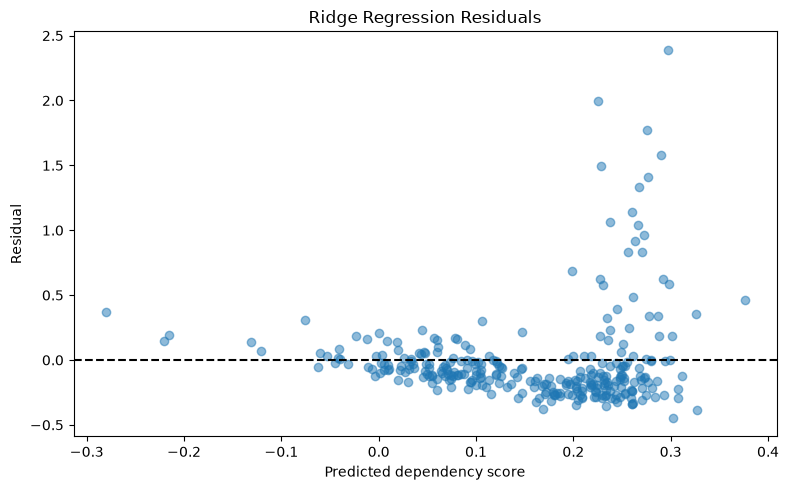

Mean residual: -0.0156
Residual standard deviation: 0.3631


In [17]:
# Plotting the residuals of the Ridge regression model on the validation set
residuals = actual - val_predictions

plt.figure(figsize=(8, 5))
plt.scatter(val_predictions, residuals, alpha=0.5)
plt.axhline(0, color="black", linestyle="--")

plt.xlabel("Predicted dependency score")
plt.ylabel("Residual")
plt.title("Ridge Regression Residuals")
plt.tight_layout()
plt.show()

print("Mean residual:", round(residuals.mean(), 4))
print("Residual standard deviation:", round(residuals.std(), 4))

In [18]:
# Display the top surface genes ranked by predicted dependency score
ranking = val.copy()

ranking["predicted_dependency"] = val_predictions
ranking["actual_dependency"] = y_val.to_numpy()
ranking["absolute_error"] = np.abs(ranking["actual_dependency"] - ranking["predicted_dependency"])

surface_ranking = (
    ranking[ranking["is_surface"].astype(bool)]
    .sort_values("predicted_dependency", ascending=False)
)

display(surface_ranking[["predicted_dependency", "actual_dependency", "absolute_error"]].head(15))

,predicted_dependency,actual_dependency,absolute_error
sample,,,
MARCKSL1,0.311734,0.186268,0.125466
ZDHHC5,0.307875,0.011439,0.296435
SLC3A2,0.287815,0.473682,0.185867
EPN1,0.283556,-0.004669,0.288225
ERBB3,0.273768,0.138888,0.134880
PFDN1,0.261365,0.746865,0.485499
TSPAN15,0.259432,-0.034055,0.293487
SNAP23,0.257288,0.505550,0.248262
SEMA4D,0.252588,-0.006933,0.259521


In [19]:
# Display the top surface genes ranked by predicted dependency score
ranking = val.copy()

ranking["predicted_dependency"] = val_predictions
ranking["actual_dependency"] = y_val.to_numpy()
ranking["absolute_error"] = np.abs(ranking["actual_dependency"] - ranking["predicted_dependency"])

surface_ranking = (
    ranking[ranking["is_surface"].astype(bool)]
    .sort_values("predicted_dependency", ascending=False)
)

display(surface_ranking[["predicted_dependency", "actual_dependency", "absolute_error"]].head(15))

,predicted_dependency,actual_dependency,absolute_error
sample,,,
MARCKSL1,0.311734,0.186268,0.125466
ZDHHC5,0.307875,0.011439,0.296435
SLC3A2,0.287815,0.473682,0.185867
EPN1,0.283556,-0.004669,0.288225
ERBB3,0.273768,0.138888,0.134880
PFDN1,0.261365,0.746865,0.485499
TSPAN15,0.259432,-0.034055,0.293487
SNAP23,0.257288,0.505550,0.248262
SEMA4D,0.252588,-0.006933,0.259521


## Part 6: Gradient Boosting Model

In [21]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance


# Search current working directory and Downloads folder for the data folder
data_folder = Path(".")

In [22]:
# Load the training and validation data, and set up the feature and target columns
train = pd.read_csv(data_folder / "checkpoint1_train.csv").set_index("sample")
val = pd.read_csv(data_folder / "checkpoint1_validation.csv").set_index("sample")
feature_cols = ["mean_expression", "enrichment", "expression_variability", "amplification_frequency"]
target_col = "dependency_score"

# Set up the training and validation data, and create a surface mask for the validation set
X_train, y_train = train[feature_cols], train[target_col]
X_val, y_val = val[feature_cols], val[target_col]
surface_mask = val["is_surface"].to_numpy(dtype=bool)

print("Train:", len(train), "(surface:", int(train.is_surface.sum()), ")")
print("Validation:", len(val), "(surface:", int(surface_mask.sum()), ")")
print("No test set accessed.")

Train: 1400 (surface: 175 )
Validation: 300 (surface: 38 )
No test set accessed.


In [23]:
# Define the hyperparameter configurations to be tested for the Gradient Boosting Regressor
configs = [
    {"n_estimators": 100, "learning_rate": 0.05, "max_depth": 2, "min_samples_leaf": 5},
    {"n_estimators": 200, "learning_rate": 0.05, "max_depth": 2, "min_samples_leaf": 5},
    {"n_estimators": 300, "learning_rate": 0.03, "max_depth": 2, "min_samples_leaf": 5},
    {"n_estimators": 100, "learning_rate": 0.05, "max_depth": 3, "min_samples_leaf": 5},
    {"n_estimators": 200, "learning_rate": 0.05, "max_depth": 3, "min_samples_leaf": 5},
    {"n_estimators": 300, "learning_rate": 0.03, "max_depth": 3, "min_samples_leaf": 10},
    {"n_estimators": 150, "learning_rate": 0.10, "max_depth": 2, "min_samples_leaf": 10},
]

# Build the model using a median imputer and a Gradient Boosting Regressor with the specified hyperparameters
def build_model(config, features=feature_cols):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("gb", GradientBoostingRegressor(loss="squared_error", random_state=42, **config))
    ])

# Score the model's predictions using MAE, RMSE, R2, and Spearman correlation
def score(y, pred):
    y = np.asarray(y); pred = np.asarray(pred)

    # Calculate Spearman correlation only if there are at least 3 samples\
    spearman_rho = spearmanr(y, pred).statistic if len(y) >= 3 and np.std(y) > 0 and np.std(pred) > 0 else np.nan

    return {"MAE": mean_absolute_error(y, pred), "RMSE": np.sqrt(mean_squared_error(y, pred)),  "R2": r2_score(y, pred), "Spearman": spearman_rho}

rows = []
models = {}

# For each hyperparameter configuration, build the model, fit it to the training data, 
# and evaluate it on the validation data. Store the results in a DataFrame for comparison
for i, config in enumerate(configs):
    model = build_model(config)
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    rows.append({"config_id": i, **config, "validation_MAE": mean_absolute_error(y_val, pred),
                 "surface_MAE": mean_absolute_error(y_val.to_numpy()[surface_mask], pred[surface_mask])})
    models[i] = model

tuning = pd.DataFrame(rows).sort_values(["validation_MAE", "config_id"])
display(tuning)

# Select the best model based on the lowest validation MAE and evaluate it
best_id = int(tuning.iloc[0]["config_id"])
best_config = configs[best_id]
best_model = models[best_id]
val_predictions = best_model.predict(X_val)


print("Selected configuration:", best_id, best_config)

,config_id,n_estimators,learning_rate,max_depth,min_samples_leaf,validation_MAE,surface_MAE
1,1,200,0.05,2,5,0.206664,0.183577
0,0,100,0.05,2,5,0.206951,0.181472
2,2,300,0.03,2,5,0.207008,0.182387
3,3,100,0.05,3,5,0.207927,0.191801
6,6,150,0.10,2,10,0.208054,0.178125
5,5,300,0.03,3,10,0.208137,0.187282
4,4,200,0.05,3,5,0.210099,0.203939


Selected configuration: 1 {'n_estimators': 200, 'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 5}


In [24]:
# Evaluate the best model and a constant baseline model on the validation set
constant = DummyRegressor(strategy="mean").fit(X_train, y_train)
constant_pred = constant.predict(X_val)
metric_rows = []

# Evaluate both the constant baseline model and the best Gradient Boosting model
for model_name, pred in [("Constant", constant_pred), ("Gradient boosting", val_predictions)]:
    for subset, mask in [("Overall", np.ones(len(val), dtype=bool)), ("Surface", surface_mask)]:
        metric_rows.append({"Model": model_name, "Subset": subset, "N": int(mask.sum()),
                            **score(y_val.to_numpy()[mask], pred[mask])})

metrics = pd.DataFrame(metric_rows)
display(metrics.round(4))

/var/folders/54/4rmgmq8n02zg15qd9jgvd3j00000gn/T/ipykernel_45683/993249257.py:24: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_rho = spearmanr(y, pred).statistic if len(y) >= 3 and np.std(y) > 0 and np.std(pred) > 0 else np.nan
/var/folders/54/4rmgmq8n02zg15qd9jgvd3j00000gn/T/ipykernel_45683/993249257.py:24: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_rho = spearmanr(y, pred).statistic if len(y) >= 3 and np.std(y) > 0 and np.std(pred) > 0 else np.nan


,Model,Subset,N,MAE,RMSE,R2,Spearman
0,Constant,Overall,300,0.2355,0.3874,-0.0037,NaN
1,Constant,Surface,38,0.1970,0.2372,-0.1790,NaN
2,Gradient boosting,Overall,300,0.2067,0.3651,0.1085,0.4121
3,Gradient boosting,Surface,38,0.1836,0.2973,-0.8525,0.4605


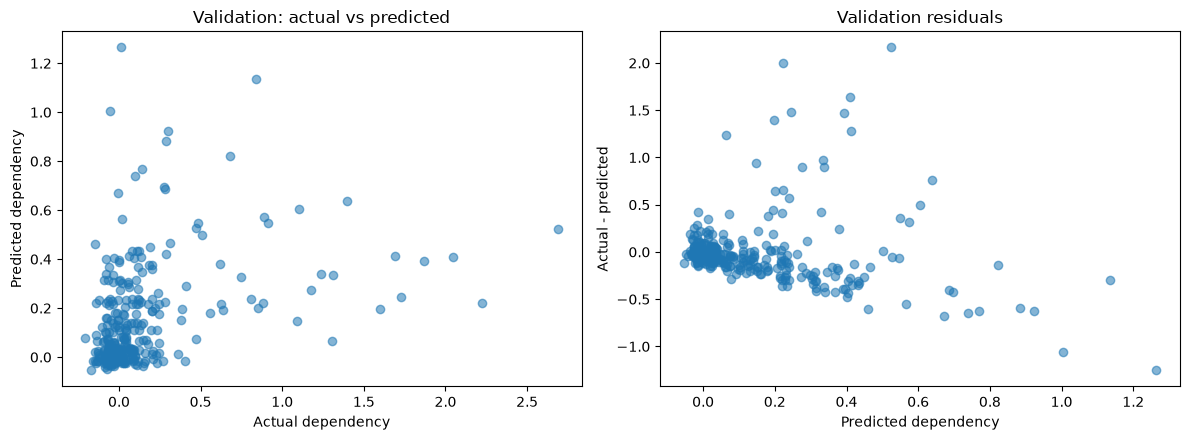

,feature,tree_importance
2,expression_variability,0.368917
0,mean_expression,0.351835
1,enrichment,0.244649
3,amplification_frequency,0.034599


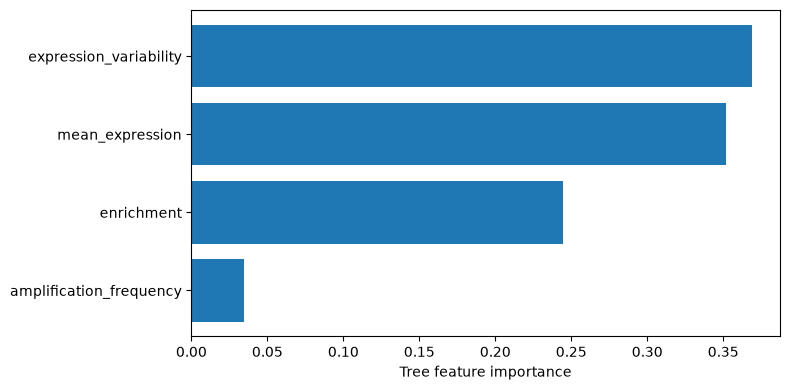

,feature,MAE_increase_mean,MAE_increase_sd
2,expression_variability,0.03048,0.00576
1,enrichment,0.02259,0.00464
0,mean_expression,0.01600,0.00525
3,amplification_frequency,0.00236,0.00116


In [25]:
# Plot the actual vs predicted dependency scores and the residuals for the best model on the validation set
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_val, val_predictions, alpha=0.55)
axes[0].set(xlabel="Actual dependency", ylabel="Predicted dependency", title="Validation: actual vs predicted")
residuals = y_val.to_numpy() - val_predictions

axes[1].scatter(val_predictions, residuals, alpha=0.55)
axes[1].set(xlabel="Predicted dependency", ylabel="Actual - predicted", title="Validation residuals")

plt.tight_layout(); plt.show()

importance = pd.DataFrame({"feature": feature_cols, "tree_importance": best_model.named_steps["gb"].feature_importances_}).sort_values("tree_importance", ascending=False)
display(importance)

plt.figure(figsize=(8, 4)); plt.barh(importance.feature[::-1], importance.tree_importance[::-1]); plt.xlabel("Tree feature importance"); plt.tight_layout(); plt.show()

permutation = permutation_importance(best_model, X_val, y_val, n_repeats=20, random_state=42,
                              scoring="neg_mean_absolute_error")

perm_df = pd.DataFrame({"feature": feature_cols, "MAE_increase_mean": permutation.importances_mean,
                        "MAE_increase_sd": permutation.importances_std}).sort_values("MAE_increase_mean", ascending=False)

display(perm_df.round(5))

In [27]:
ablation_rows = []

# Evaluate the model performance with all features and without the amplification frequency feature
for feature_group, cols in [("All four", feature_cols),
                          ("No amplification", [c for c in feature_cols if c != "amplification_frequency"])]:
    for i, config in enumerate(configs):
        trained_model = build_model(config, cols).fit(train[cols], y_train)
        model_pred = trained_model.predict(val[cols])
        ablation_rows.append({"Feature set": feature_group, "config_id": i,
                             "MAE": mean_absolute_error(y_val, model_pred),
                             "Surface MAE": mean_absolute_error(y_val.to_numpy()[surface_mask], model_pred[surface_mask]),
                             "Spearman": score(y_val, model_pred)["Spearman"]})

ablation_all = pd.DataFrame(ablation_rows)
ablation_best = ablation_all.sort_values(["MAE", "config_id"]).groupby("Feature set", as_index=False).first()
display(ablation_best.round(5))

,Feature set,config_id,MAE,Surface MAE,Spearman
0,All four,1,0.20666,0.18358,0.41210
1,No amplification,0,0.20781,0.18274,0.40716


In [28]:
random_generator = np.random.default_rng(42)
bootstrap_rows = []

# For each subset (Overall and Surface), perform bootstrap resampling to estimate the confidence intervals for MAE and Spearman correlation
for subset, mask in [("Overall", np.ones(len(val), dtype=bool)), ("Surface", surface_mask)]:
    yt = y_val.to_numpy()[mask]; yp = val_predictions[mask]
    # Perform 1000 bootstrap resamples to calculate MAE and Spearman correlation for each resample
    for _ in range(1000):
        idx = random_generator.integers(0, len(yt), len(yt))
        bootstrap_rows.append({"Subset": subset, "MAE": mean_absolute_error(yt[idx], yp[idx]),
            "Spearman": score(yt[idx], yp[idx])["Spearman"]})

# Calculate the 2.5% and 97.5% quantiles for MAE and Spearman correlation for each subset to estimate the confidence intervals
boot = pd.DataFrame(bootstrap_rows)
confidence_intervals_rows = []
for subset, subset_group in boot.groupby("Subset"):
    for metric in ["MAE", "Spearman"]:
        confidence_intervals_rows.append({"Subset": subset, "Metric": metric,
                        "2.5%": subset_group[metric].quantile(.025), "97.5%": subset_group[metric].quantile(.975)})

display(pd.DataFrame(confidence_intervals_rows).round(4))

,Subset,Metric,2.5%,97.5%
0,Overall,MAE,0.1732,0.2447
1,Overall,Spearman,0.3071,0.5150
2,Surface,MAE,0.1182,0.2633
3,Surface,Spearman,0.1954,0.6774


## Part 8: Model Comparison

In [29]:
# Compare validation peformance for all four models:
comparison = pd.DataFrame({
    "Model": [
        "Constant Baseline",
        "Random Forest",
        "Ridge Regression",
        "Gradient Boosting"
    ],
    "Overall MAE": [0.2355, 0.2040, 0.2190, 0.2067],
    "Surface MAE": [0.1970, 0.1671, 0.1840, 0.1836],
    "Overall Spearman": [np.nan, 0.4007, 0.4141, 0.4121],
    "Surface Spearman": [np.nan, 0.4468, 0.3588, 0.4605]
})

display(comparison)

,Model,Overall MAE,Surface MAE,Overall Spearman,Surface Spearman
0,Constant Baseline,0.2355,0.1970,NaN,NaN
1,Random Forest,0.2040,0.1671,0.4007,0.4468
2,Ridge Regression,0.2190,0.1840,0.4141,0.3588
3,Gradient Boosting,0.2067,0.1836,0.4121,0.4605


## Model Evaluation

Random Forest has the lowest Overall Mean Absolute Error (MAE) and the lowest Surface Mean Absolute Error (MAE). The trade-off with Random Forest is that its Overall Spearman level is the lowest while its Surface Spearman is the second highest (0.4468). Gradient Boosting produces the highest Surface Spearman (0.4605) with the second-highest Overall Spearman correlation (0.4121). Gradient Boosting has slightly higher prediction error (MAE). These 2 models show different goals. Choosing Random Forest will prioritize lowest prediction error. Choosing Gradient Boosting will prioritize highest ranking correlation. Because we want to rank surface genes for tumor-target prioritization, Gradient Boosting is selected as the primary ranking model to achieve our desired results. The primary model was selected with validation results.

## Part 9: Test Evaluation and Final Surface Gene Ranking

In [30]:
# Load test data
test = pd.read_csv(data_folder / "checkpoint1_test.csv").set_index("sample")
# Features and target
X_test, y_test = test[feature_cols], test[target_col]
# Surface genes in test set
test_surface_mask = test["is_surface"].to_numpy(dtype=bool)

print("Test Genes:", len(test))
print("Surface Genes in Test Set", int(test_surface_mask.sum()))
print("Test Feature Shape:", X_test.shape)

Test Genes: 300
Surface Genes in Test Set 37
Test Feature Shape: (300, 4)


In [31]:
# Evaluate the best Gradient Boosting model on the test set
test_predictions = best_model.predict(X_test)

# Overall test metrics
test_mae = mean_absolute_error(y_test, test_predictions)
test_spearman = spearmanr(y_test, test_predictions).statistic

# Surface Test Metrics
surface_actual = y_test[test_surface_mask]
surface_pred = test_predictions[test_surface_mask]

surface_mae = mean_absolute_error(surface_actual, surface_pred)
surface_spearman = spearmanr(surface_actual, surface_pred).statistic

print("Gradient Boosting Test Results")
print("Overall MAE:", round(test_mae, 4))
print("Overall Spearman:", round(test_spearman, 4))
print("Surface MAE:", round(surface_mae, 4))
print("Surface Spearman:", round(surface_spearman, 4))

Gradient Boosting Test Results
Overall MAE: 0.2194
Overall Spearman: 0.4433
Surface MAE: 0.1863
Surface Spearman: 0.3295


## Part 10: Rank the Surface Genes

In [32]:
# Create table of test genes and predictions
ranked_genes = test.copy()
ranked_genes["predicted_dependency"] = test_predictions

# Only surface genes
ranked_genes = ranked_genes[ranked_genes["is_surface"] == True]

# Rank genes with predicted dependency score (Highest to lowest)
ranked_genes = ranked_genes.sort_values(
    by="predicted_dependency", 
    ascending=False
)

# Show the top 20 surface genes
display(ranked_genes.head(20))

,mean_expression,expression_variability,amplification_frequency,dependency_score,is_surface,enrichment,predicted_dependency
sample,,,,,,,
ATP1A1,14.132439,0.723350,0.003876,1.583250,True,-0.369403,0.627315
FLOT2,11.691669,0.407070,0.015504,0.118518,True,-0.014732,0.616734
PIGW,7.866779,0.569911,0.005814,0.195372,True,0.613568,0.408940
S100A16,11.611105,1.195121,0.129845,0.032106,True,0.901052,0.399788
PIGN,8.863046,0.550223,0.001938,0.031123,True,0.134033,0.263749
PLSCR1,10.373444,0.742220,0.013566,-0.050832,True,0.090604,0.262099
CLTB,10.296618,0.731147,0.025194,0.149142,True,-0.202878,0.227996
UBE2B,10.174469,0.491322,0.000000,-0.039002,True,-0.381207,0.203238
POLE,9.470667,0.804061,0.003876,1.535408,True,0.920941,0.197909


In [33]:
# Make the table cleaner
top_genes = ranked_genes.head(20).copy()

top_genes = top_genes[
    [
        "predicted_dependency",
        "mean_expression",
        "enrichment",
        "expression_variability",
        "amplification_frequency",
    ]
]

# Rank numbers and gene names
top_genes = top_genes.reset_index()
top_genes = top_genes.rename(columns={"sample": "Gene"})
top_genes.insert(0, "Rank", range(1, len(top_genes) + 1))

display(top_genes.round(4))
print(test.columns.tolist())

,Rank,Gene,predicted_dependency,mean_expression,enrichment,expression_variability,amplification_frequency
0,1,ATP1A1,0.6273,14.1324,-0.3694,0.7233,0.0039
1,2,FLOT2,0.6167,11.6917,-0.0147,0.4071,0.0155
2,3,PIGW,0.4089,7.8668,0.6136,0.5699,0.0058
3,4,S100A16,0.3998,11.6111,0.9011,1.1951,0.1298
4,5,PIGN,0.2637,8.8630,0.1340,0.5502,0.0019
5,6,PLSCR1,0.2621,10.3734,0.0906,0.7422,0.0136
6,7,CLTB,0.2280,10.2966,-0.2029,0.7311,0.0252
7,8,UBE2B,0.2032,10.1745,-0.3812,0.4913,0.0000
8,9,POLE,0.1979,9.4707,0.9209,0.8041,0.0039
9,10,CDH3,0.1184,10.2117,2.3599,1.9951,0.0058


['mean_expression', 'expression_variability', 'amplification_frequency', 'dependency_score', 'is_surface', 'enrichment']


## Surface Gene Eligibility

Surface associated genes were chosen using the Human Protein Atlas (HPA) localization data. The annotation "Plasma membrane" in the localization fields were identified as surface associated genes. With this filter, 2,263 genes in HPA were identified. Only 1,955 of the 2,263 genes were present in the combined gene dataset created before training, validation, and test sets in Checkpoint 1.

The final Gradient Boosting model ranked 37 surface associated genes in the test set by predicted dependency score. Predicted dependency score was calculated with the machine-learning model trained using DepMap data. Higher predicted dependency scores indicate that cancer cells are predicted to depend more strongly on these top 20 genes for survival and growth. The top 20 genes are listed above.

However, a limitation is that plasma-membrane localization does not confirm that a protein can be reached outside the cell or can be used as a target for CAR-T cell therapy.

## Part 11: Top 20 Surface Gene Horizontal Bar Chart

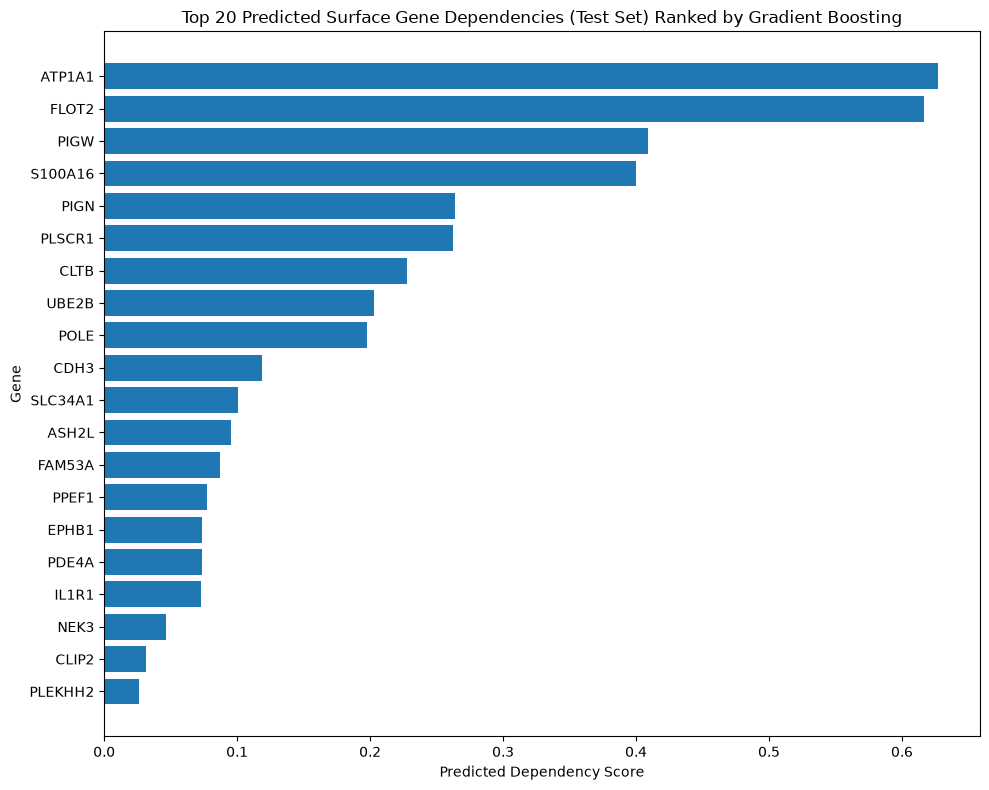

In [34]:
plt.figure(figsize=(10, 8))

plt.barh(
    top_genes["Gene"],
    top_genes["predicted_dependency"]
)

plt.xlabel("Predicted Dependency Score")
plt.ylabel("Gene")
plt.title("Top 20 Predicted Surface Gene Dependencies (Test Set) Ranked by Gradient Boosting")

#highest ranked gene at the top
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("top20_surface_genes.png", dpi=300, bbox_inches="tight")
plt.show()